# Data Visualization

In [1]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import medmnist
import numpy as np
import os
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision import models
from medmnist import INFO, Evaluator
from tqdm import tqdm
from monai.transforms import (
    Compose,
    EnsureChannelFirst,
    RandAdjustContrast,
    RandRotate,
    RandZoom,
    Resize,
    ScaleIntensityRangePercentiles,
    ToTensor,
    Lambda
)

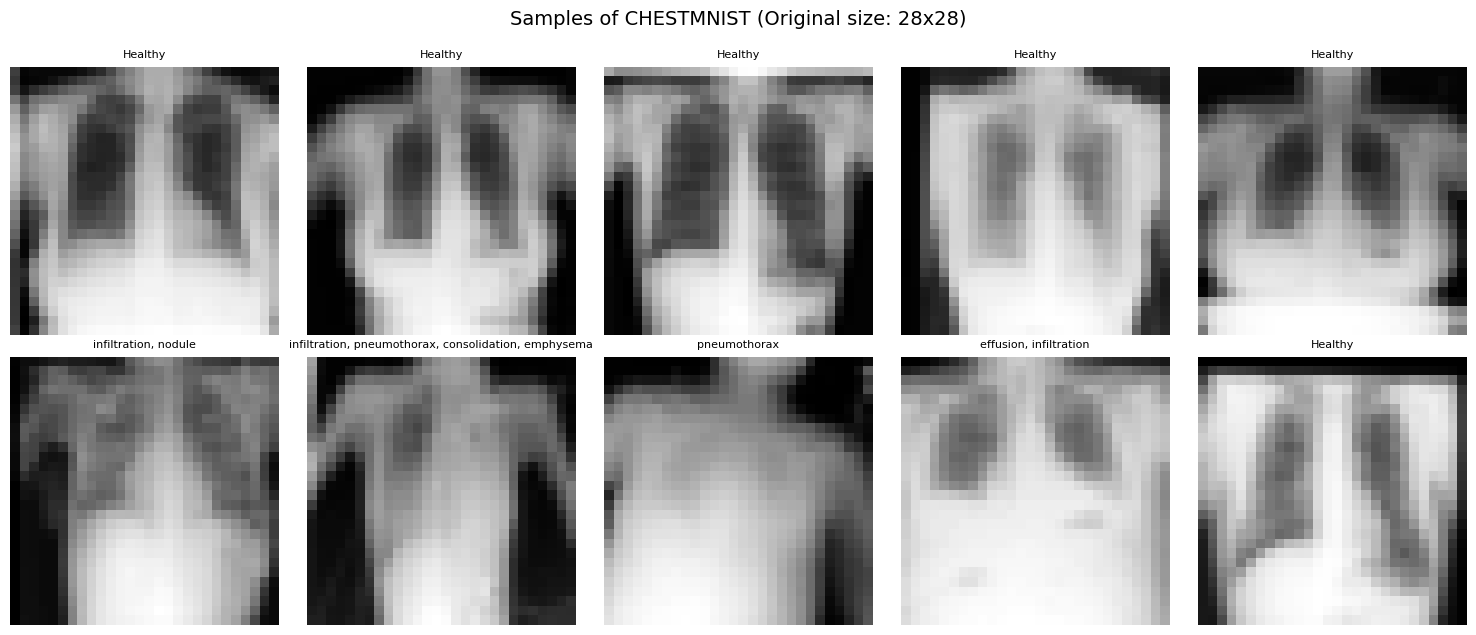

In [15]:
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
train_dataset = medmnist.ChestMNIST(split='train', transform=None, download=True, size=28)

def show_original_samples(dataset, info, num_images=10, title="Title"):
    # Label names
    labels_map = info['label']
    plt.figure(figsize=(15, 6))
    for i in range(num_images):
        # Image and label
        img = dataset.imgs[i] 
        target = dataset.labels[i]
        
        # Detect pathologies present (where value is 1)
        patologies = [labels_map[str(j)] for j, val in enumerate(target) if val == 1]
        title_img = ", ".join(patologies) if patologies else "Healthy"
        
        plt.subplot(2, 5, i + 1)
        plt.imshow(img, cmap='gray')
        plt.title(title_img, fontsize=8, wrap=True)
        plt.axis('off')
        
    plt.tight_layout()
    plt.suptitle(title, fontsize=14, y=1.05)
    plt.show()

show_original_samples(train_dataset, info, num_images=10, title=f"Samples of {DATA_FLAG.upper()} (Original size: 28x28)")

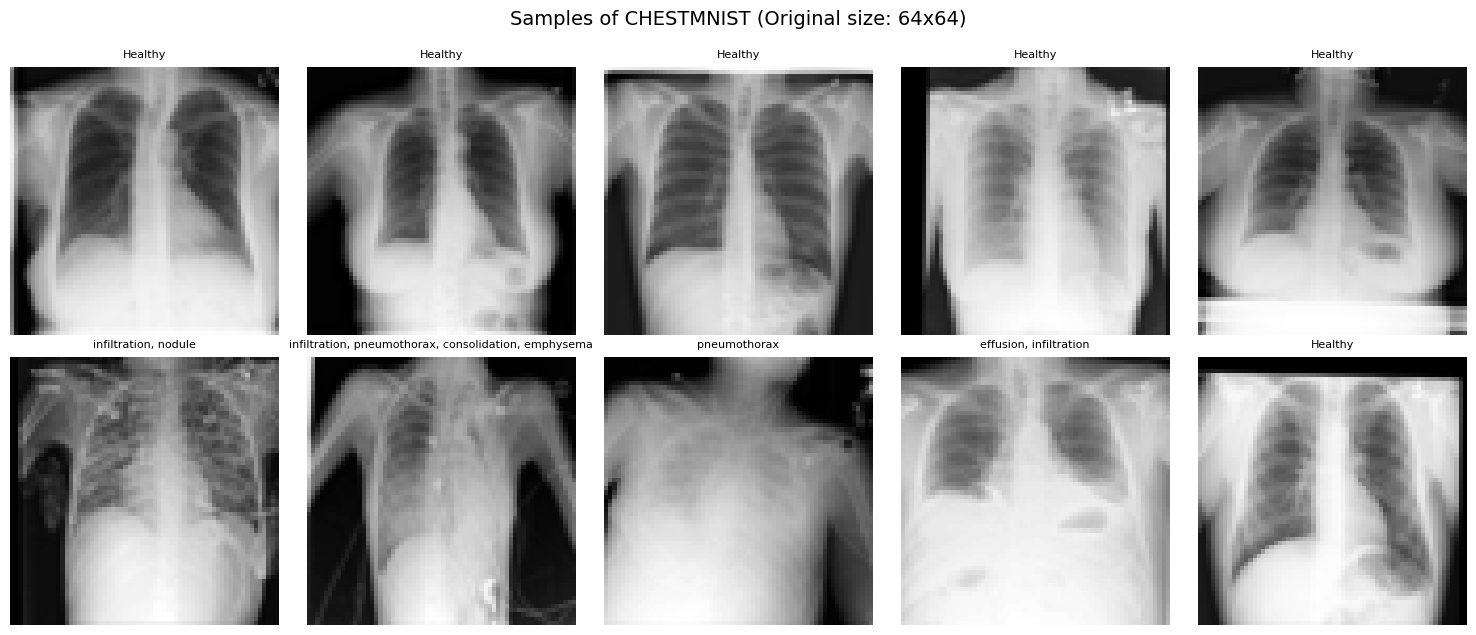

In [16]:
train_dataset = medmnist.ChestMNIST(split='train', transform=None, download=True, size=64)
show_original_samples(train_dataset, info, num_images=10, title=f"Samples of {DATA_FLAG.upper()} (Original size: 64x64)")

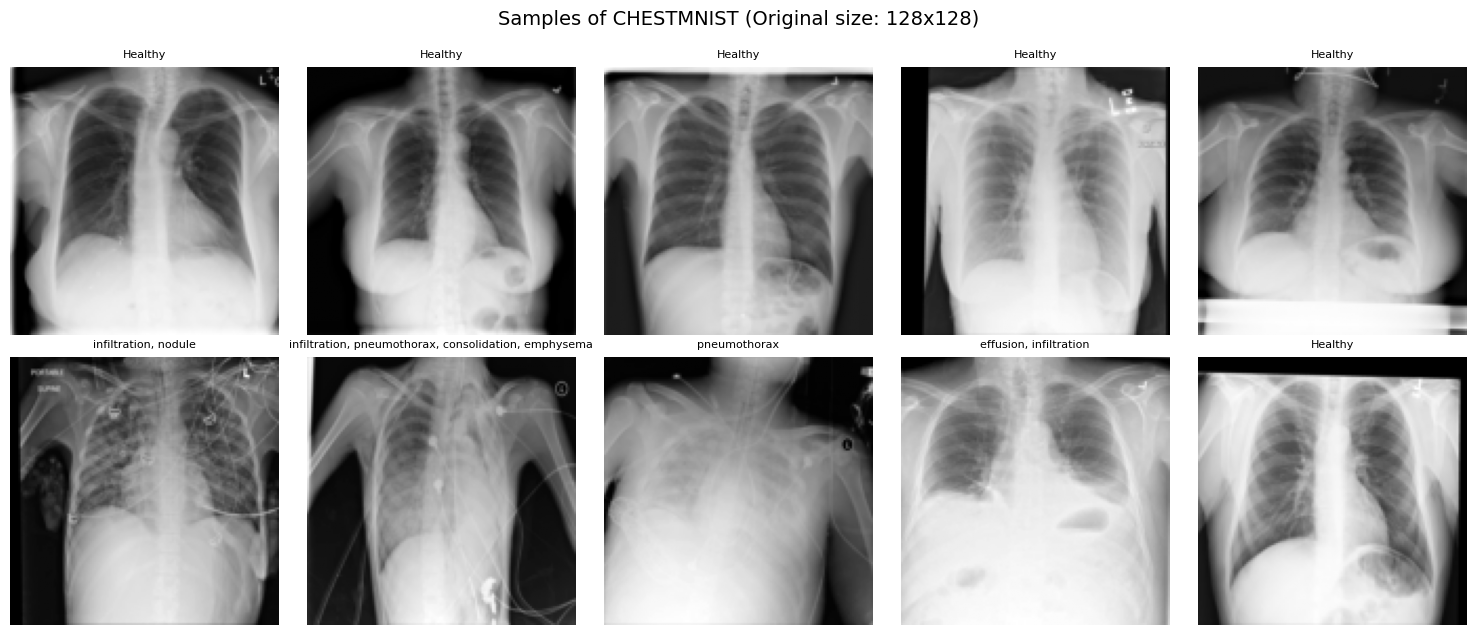

In [17]:
train_dataset = medmnist.ChestMNIST(split='train', transform=None, download=True, size=128)
show_original_samples(train_dataset, info, num_images=10, title=f"Samples of {DATA_FLAG.upper()} (Original size: 128x128)")

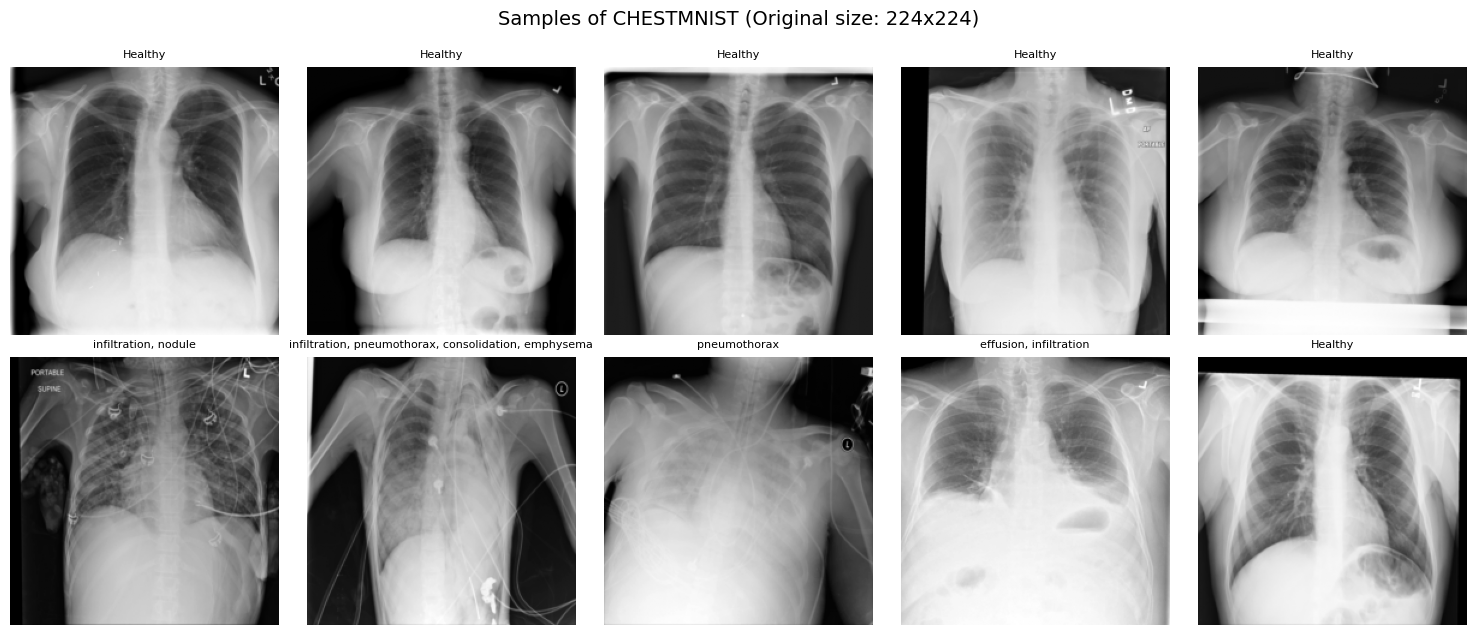

In [18]:
train_dataset = medmnist.ChestMNIST(split='train', transform=None, download=True, size=224)
show_original_samples(train_dataset, info, num_images=10, title=f"Samples of {DATA_FLAG.upper()} (Original size: 224x224)")

## Data Augmentation with MONAI for train

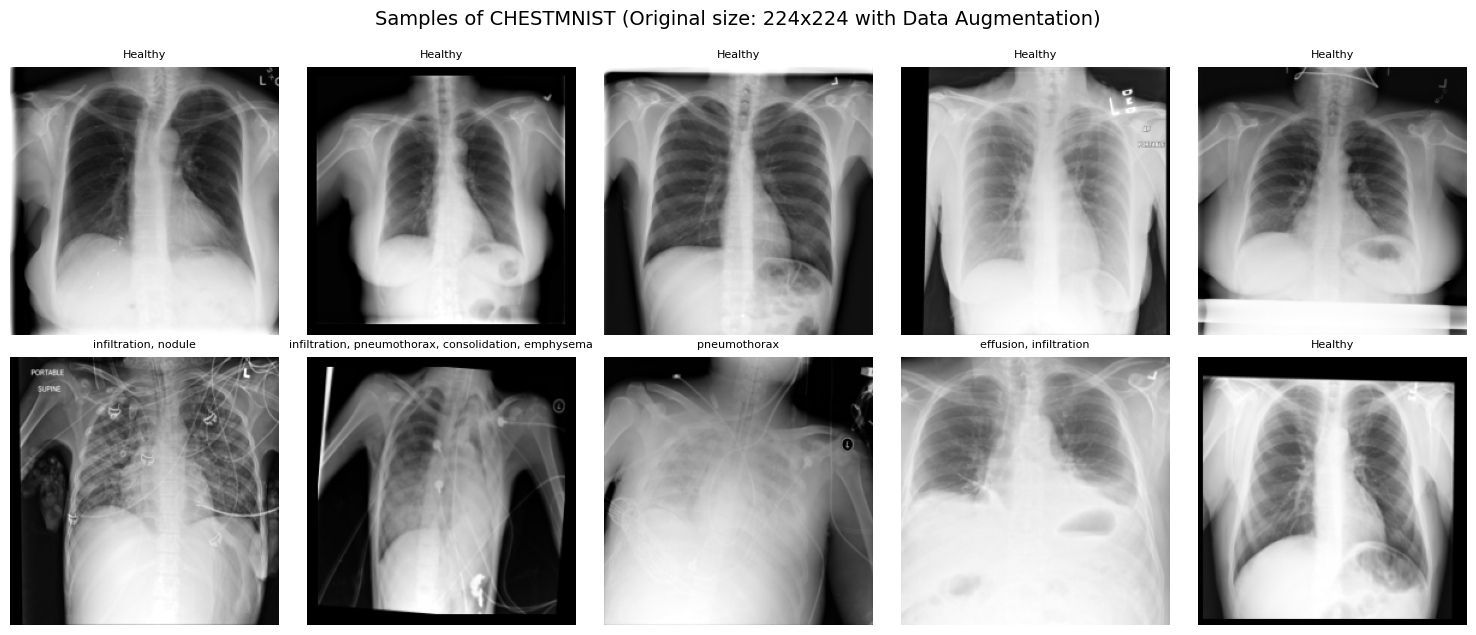

In [19]:
# Data Transforms
train_transforms = Compose([
    Lambda(lambda x: np.array(x).astype(np.float32)),
    EnsureChannelFirst(channel_dim='no_channel'), # Format (C, H, W)

    # Advanced Clinical Normalization
    # It is much more robust for medical use than normalizing with ImageNet 
    # By using the 0.5 to 99.5 percentile, burned-out pixels or pure blacks that are noise are eliminated, and the useful contrast of the anatomy (lungs, heart) is stretched to the [0, 1] range.
    ScaleIntensityRangePercentiles(
        lower=0.5, upper=99.5, b_min=0.0, b_max=1.0, clip=True
    ),

    # Random Data Augmentation
    
    # Contrast Variation (Probability of 30%)
    RandAdjustContrast(prob=0.3, gamma=(0.7, 1.3)),

    # Small Rotation (Probability of 20%, +/- 7 grades)
    RandRotate(prob=0.2, range_x=7.0 * (np.pi / 180.0), padding_mode="constant", mode="bilinear"),

    # Random Zoom (Probability of 20%, between 0.9x and 1.1x)
    RandZoom(prob=0.2, min_zoom=0.9, max_zoom=1.1, padding_mode="constant", mode="bilinear"),

    # Final format
    Resize(spatial_size=(224, 224)),

    # 3 channels
    Lambda(lambda x: np.repeat(x, 3, axis=0) if x.shape[0] == 1 else x),
    ToTensor(),
    
    # ImageNet normalization
    #NormalizeUTF8d(
    #    keys=["image"], 
    #    subtrahend=[0.485, 0.456, 0.406], 
    #    divisor=[0.229, 0.224, 0.225]
    #)
])

def show_augmented_samples(dataset, info, num_images=10, title="Title"):
    labels_map = info['label']
    plt.figure(figsize=(15, 6))
    
    for i in range(num_images):
        img, target = dataset[i]
        
        # From Tensor to NumPy
        if torch.is_tensor(img):
            img = img.cpu().numpy()
        
        # If has 3 channels (3, 224, 224), transform to (224, 224, 3)
        if img.ndim == 3 and img.shape[0] == 3:
            img = img.transpose(1, 2, 0)
        # If has 1 channel (1, 224, 224), transform to (224, 224)
        elif img.ndim == 3 and img.shape[0] == 1:
            img = img.squeeze(0)
        
        patologies = [labels_map[str(j)] for j, val in enumerate(target) if val == 1]
        label_text = ", ".join(patologies) if patologies else "Healthy"
        
        plt.subplot(2, 5, i + 1)
        # cmap='gray' se ignora automáticamente si la imagen es RGB (3 canales)
        plt.imshow(img, cmap='gray', vmin=0, vmax=1)
        plt.title(label_text, fontsize=8, wrap=True)
        plt.axis('off')
        
    plt.tight_layout()
    plt.suptitle(title, fontsize=14, y=1.05)
    plt.show()

train_dataset = medmnist.ChestMNIST(split='train', transform=train_transforms, download=True, size=224)
show_augmented_samples(train_dataset, info, num_images=10, title=f"Samples of {DATA_FLAG.upper()} (Original size: 224x224 with Data Augmentation)")

## Distribution of diseases

(78468, 14)
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 1 0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 1 1 0 1 0 0 0]
 [0 0 0 0 0 0 0 1 0 0 0 0 0 0]
 [0 0 1 1 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0]]
{'0': 'atelectasis', '1': 'cardiomegaly', '2': 'effusion', '3': 'infiltration', '4': 'mass', '5': 'nodule', '6': 'pneumonia', '7': 'pneumothorax', '8': 'consolidation', '9': 'edema', '10': 'emphysema', '11': 'fibrosis', '12': 'pleural', '13': 'hernia'}


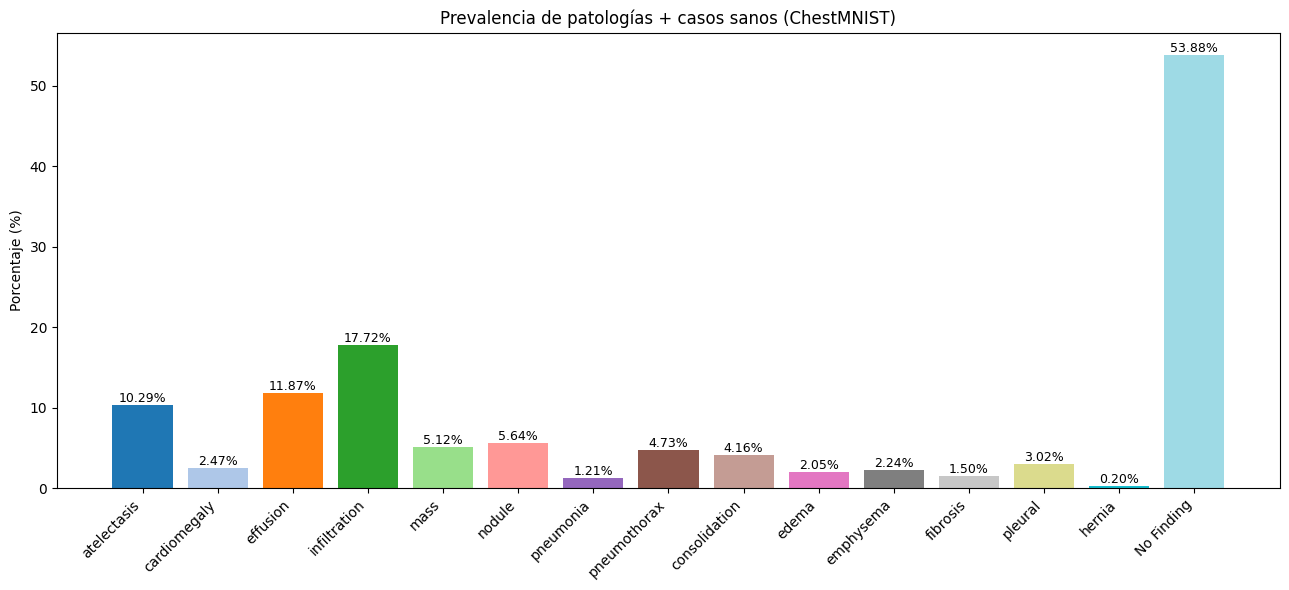

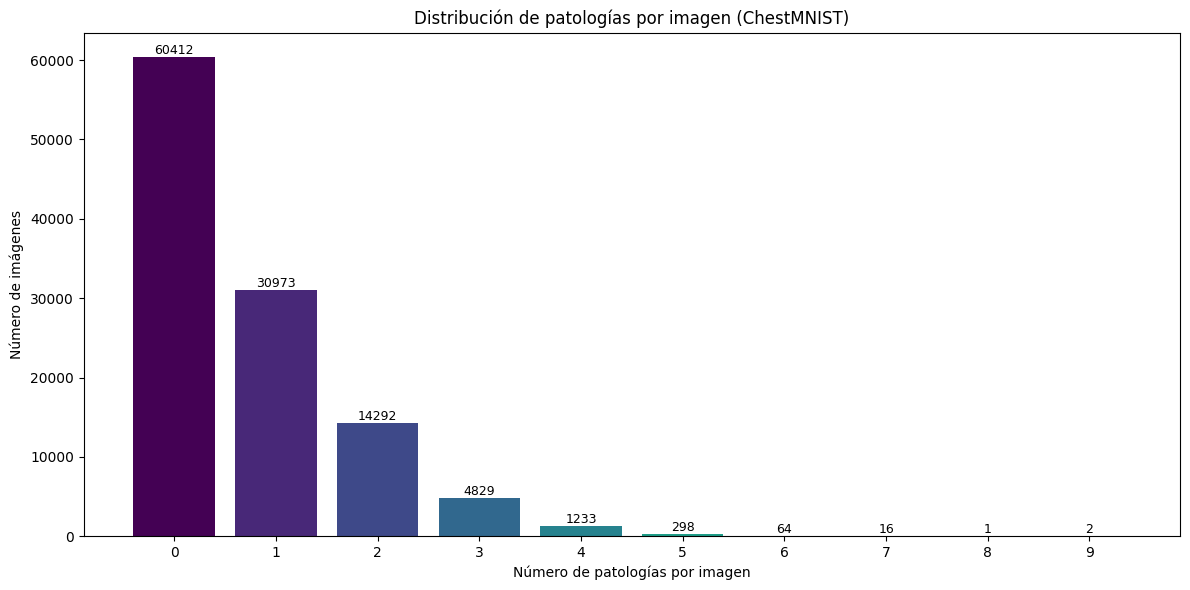

In [21]:
DATA_FLAG = 'chestmnist'
info = INFO[DATA_FLAG]
train_dataset = medmnist.ChestMNIST(split='train', transform=None, download=True, size=28)
val_dataset = medmnist.ChestMNIST(split='val', transform=None, download=True, size=28)
test_dataset = medmnist.ChestMNIST(split='test', transform=None, download=True, size=28)
len(train_dataset)
len(val_dataset)
len(test_dataset)
print(train_dataset.labels.shape)
print(train_dataset.labels[:10])
print(info['label'])

# Concatenar labels
all_labels = np.vstack([
    train_dataset.labels,
    val_dataset.labels,
    test_dataset.labels
])

# Porcentajes por patología
percentages = all_labels.mean(axis=0) * 100

# 🔹 Porcentaje de imágenes sin patologías (todas 0)
no_disease_pct = (np.sum(all_labels.sum(axis=1) == 0) / len(all_labels)) * 100

# Labels
label_map = info['label']
label_names = [label_map[k] for k in sorted(label_map, key=int)]

# Añadir "No Finding" (o como quieras llamarlo)
label_names.append('No Finding')
percentages = np.append(percentages, no_disease_pct)

# Colores
colors = plt.cm.tab20(np.linspace(0, 1, len(label_names)))

# Plot
plt.figure(figsize=(13, 6))
bars = plt.bar(label_names, percentages, color=colors)

plt.xticks(rotation=45, ha='right')
plt.ylabel('Porcentaje (%)')
plt.title('Prevalencia de patologías + casos sanos (ChestMNIST)')

# Valores encima
for bar, value in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.2f}%',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
plt.show()


# Concatenar labels
all_labels = np.vstack([
    train_dataset.labels,
    val_dataset.labels,
    test_dataset.labels
])

# Número de patologías por imagen
num_pathologies = all_labels.sum(axis=1)

# Contar cuántas imágenes tienen 0, 1, 2, ..., 14 patologías
counts = np.bincount(num_pathologies.astype(int))

# Eje X (número de patologías)
x = np.arange(len(counts))

# Colores
colors = plt.cm.viridis(np.linspace(0, 1, len(counts)))

# Plot
plt.figure(figsize=(12, 6))
bars = plt.bar(x, counts, color=colors)

plt.xlabel('Número de patologías por imagen')
plt.ylabel('Número de imágenes')
plt.title('Distribución de patologías por imagen (ChestMNIST)')

# Añadir valores encima
for bar, value in zip(bars, counts):
    if value > 0:
        plt.text(
            bar.get_x() + bar.get_width()/2,
            value,
            str(value),
            ha='center',
            va='bottom',
            fontsize=9
        )

plt.xticks(x)
plt.tight_layout()
plt.show()